/mnt/d/jinr/SNEWPY/snewpy_venv/lib/python3.10/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


6106.581431383964


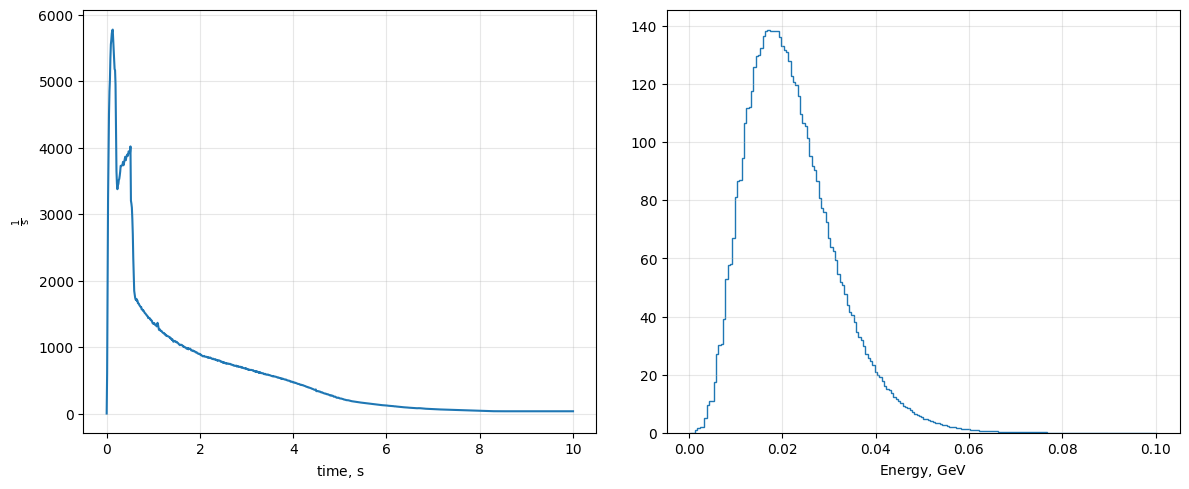

In [1]:
import astropy.units as u
import numpy as np
from snewpy.models import ccsn
from snewpy.flavor_transformation import AdiabaticMSW
from snewpy.neutrino import MixingParameters

# Или подавляем все предупреждения 
import warnings
warnings.filterwarnings('ignore')

#get the suernova model
model = ccsn.Bollig_2016(progenitor_mass=27<<u.Msun)
#define the sampling points
energy = np.linspace(0,100,51)<<u.MeV
time = np.linspace(0,10,1000)<<u.s

#calculate the flux
flux = model.get_flux(time, energy, distance=10<<u.kpc, 
                      flavor_xform=AdiabaticMSW(mixing_params=MixingParameters('NORMAL'))
                     )

#calculate the event rates using the RateCalculator
from snewpy.rate_calculator import RateCalculator
rc = RateCalculator()

#look at the available detectors
rc.detectors

det = rc.read_detector('scint20kt')

ibd_rate = det.run(flux)['ibd']
#get the total values vs. time bin
N_ibd_vs_T = ibd_rate.sum('energy')
#or total values vs. energy bin
N_ibd_vs_E = ibd_rate.integrate_or_sum('time')
#or total number of interactions
N_ibd_tot = ibd_rate.integrate_or_sum('time').sum('energy')
#to retrieve the number we can access the `array` member
print(N_ibd_tot.array.squeeze())

#plot individual projections
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
# ---- График временного профиля ----
x_time, dN_time = ibd_rate.project_to('time')
ax1.plot(x_time.value, dN_time.array.squeeze())
ax1.set_xlabel(f'time, {x_time.unit._repr_latex_()}')
ax1.set_ylabel(dN_time.unit._repr_latex_())
ax1.grid(True, alpha=0.3)
# ---- График энергетического спектра ----
x_energy, dN_energy = ibd_rate.project_to('energy')
ax2.stairs(edges=x_energy.value, values=dN_energy.array.squeeze())
ax2.set_xlabel(f'Energy, {x_energy.unit._repr_latex_()}')
ax2.set_ylabel(dN_energy.unit._repr_latex_())
ax2.grid(True, alpha=0.3)
# Автоматическая подгонка отступов
plt.tight_layout()
plt.show()


In [54]:
#calculate the event rates using the RateCalculator
from snewpy.rate_calculator import RateCalculator
rc = RateCalculator()
#look at the available detectors
#rc.detectors
#rc.materials
rc.efficiencies['scint20kt']

{}



*********************************************************

rho	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Ye	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat

m1	0	dm21^2	7.49e-05	dm32	0.0024381
theta12V	33.68	theta13V	8.56	theta23V	43.3	deltaCP	212

NE	51	Emin	0	Emax	100

output filename stem	:-90,0:7.49e-05,0.0024381,33.68,8.56,43.3,212:51,0,100

Number of domains	13
Domain	1:	0	to	1.2e+06
Domain	2:	1.2e+06	to	2.14e+06
Domain	3:	2.14e+06	to	3.97e+07
Domain	4:	3.97e+07	to	6.67e+07
Domain	5:	6.67e+07	to	2.888e+08
Domain	6:	2.888e+08	to	5.1465e+08
Domain	7:	5.1465e+08	to	7.5895e+08
Domain	8:	7.5895e+08	to	9.848e+08
Domain	9:	9.848e+08	to	1.2069e+09
Domain	10:	1.2069e+09	to	1.2339e+09
Domain	11:	1.2339e+09	to	1.27146e+09
Domain	12:	1.27146e+09	to	1.2

/mnt/d/jinr/SNEWPY/snewpy_latest/python/snewpy/rate_calculator.py:388: UserWarning: Efficiency not found for detector=scint20kt, channel=ibd. Using 100% efficiency
  warn(f'Efficiency not found for detector={name}, channel={ch.name}. Using 100% efficiency')
/mnt/d/jinr/SNEWPY/snewpy_latest/python/snewpy/rate_calculator.py:388: UserWarning: Efficiency not found for detector=scint20kt, channel=nue_e. Using 100% efficiency
  warn(f'Efficiency not found for detector={name}, channel={ch.name}. Using 100% efficiency')
/mnt/d/jinr/SNEWPY/snewpy_latest/python/snewpy/rate_calculator.py:388: UserWarning: Efficiency not found for detector=scint20kt, channel=nuebar_e. Using 100% efficiency
  warn(f'Efficiency not found for detector={name}, channel={ch.name}. Using 100% efficiency')
/mnt/d/jinr/SNEWPY/snewpy_latest/python/snewpy/rate_calculator.py:388: UserWarning: Efficiency not found for detector=scint20kt, channel=numu_e. Using 100% efficiency
  warn(f'Efficiency not found for detector={name}, c

6107.28384882787


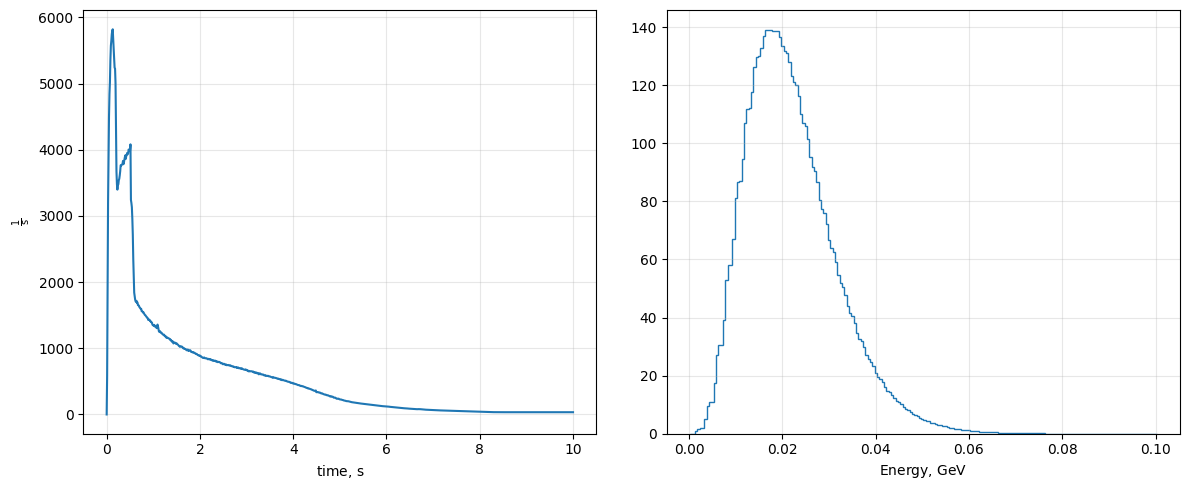

In [2]:
import astropy.units as u
import numpy as np
from snewpy.models import ccsn
from snewpy.flavor_transformation import EarthMatter
from snewpy.neutrino import MixingParameters, MassHierarchy
from astropy.coordinates import AltAz

#get the suernova model
model = ccsn.Bollig_2016(progenitor_mass=27<<u.Msun)
#define the sampling points
energy = np.linspace(0,100,51)<<u.MeV
time = np.linspace(0,10,1000)<<u.s

#calculate the flux
altaz_nh = AltAz(alt=(-90)*u.deg, az=0*u.deg)  # Сверхновая прямо под детектором
flavor_transform_nh = EarthMatter(AltAz=altaz_nh, mixing_params= MixingParameters(MassHierarchy.NORMAL))
flux_earth_nh = model.get_flux(time, energy, distance=10*u.kpc, flavor_xform=flavor_transform_nh)

#calculate the event rates using the RateCalculator
from snewpy.rate_calculator import RateCalculator
rc = RateCalculator()
det = rc.read_detector('scint20kt')

ibd_rate = det.run(flux_earth_nh)['ibd']
#ibd_rate = rc.run(flux=flux_earth_nh, detector='scint20kt', material='scint', detector_effects=True)['ibd']
#get the total values vs. time bin
N_ibd_vs_T = ibd_rate.integrate_or_sum('time')
#or total values vs. energy bin
N_ibd_vs_E = ibd_rate.sum('energy')
#or total number of interactions
N_ibd_tot = ibd_rate.integrate_or_sum('time').sum('energy')
#to retrieve the number we can access the `array` member
print(N_ibd_tot.array.squeeze())
#plot individual projections
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# ---- График временного профиля ----
x_time, dN_time = ibd_rate.project_to('time')
ax1.plot(x_time.value, dN_time.array.squeeze())
ax1.set_xlabel(f'time, {x_time.unit._repr_latex_()}')
ax1.set_ylabel(dN_time.unit._repr_latex_())
ax1.grid(True, alpha=0.3)

# ---- График энергетического спектра ----
x_energy, dN_energy = ibd_rate.project_to('energy')
ax2.stairs(edges=x_energy.value, values=dN_energy.array.squeeze())
ax2.set_xlabel(f'Energy, {x_energy.unit._repr_latex_()}')
ax2.set_ylabel(dN_energy.unit._repr_latex_())
ax2.grid(True, alpha=0.3)

# Автоматическая подгонка отступов
plt.tight_layout()
plt.show()

In [13]:
det.mass=20*u.kt#можем установить массу

In [28]:
ibd_rate = det.run(flux_earth_nh)['ibd']

/mnt/d/jinr/SNEWPY/snewpy_latest/python/snewpy/rate_calculator.py:353: RuntimeWarning: divide by zero encountered in log
  return np.interp(np.log(E)/np.log(10), xp, yp, left=0, right=0)*E*1e-38 <<u.cm**2


In [29]:
x, y = ibd_rate.project_to("energy")

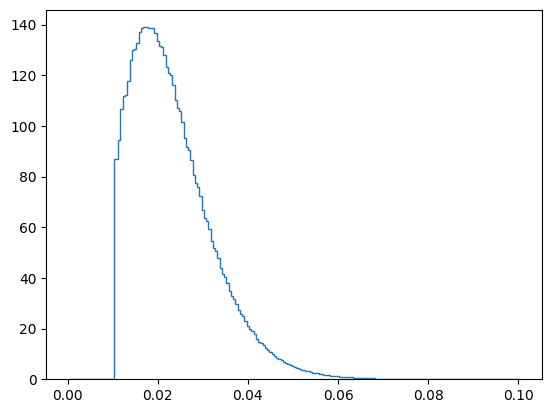

In [30]:
import matplotlib.pyplot as plt
plt.stairs(y.array.squeeze().value, x.value)#для энергии plot(x, y.array.)

In [26]:
det.channels["ibd"].efficiency

1

In [27]:
def f(energy):#функция отсекающая по энергии
    return (energy>10*u.MeV)*1
det.channels["ibd"].efficiency = f#можем менять эффективность, даже функции задавать

# Start here

In [2]:
import astropy.units as u
import numpy as np
from snewpy.models import ccsn
from snewpy.flavor_transformation import EarthMatter, AdiabaticMSW
from snewpy.neutrino import MixingParameters, MassHierarchy, Flavor
from astropy.coordinates import AltAz
from snewpy.rate_calculator import RateCalculator, Detector, DetectionChannel, SmearingMatrix
import matplotlib.pyplot as plt
# Или подавляем все предупреждения 
import warnings
warnings.filterwarnings('ignore')
    
#get the suernova model
model = ccsn.Bollig_2016(progenitor_mass=27<<u.Msun)
#define the sampling points
energy = np.linspace(1,100,800)<<u.MeV
time = np.linspace(0,2,800)<<u.s
rc = RateCalculator()
det = rc.read_detector('scint20kt')


/mnt/d/jinr/SNEWPY/snewpy_venv/lib/python3.10/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


In [3]:
#создание сврего детектора
xsec_ibd=rc.load_xsec('ibd',Flavor.NU_E_BAR)#сечение для ibd электронное антинейтрино из SNOwGLoBES
e_true  = np.arange(0,50,0.2)<<u.MeV #энергия нейтрино в пучку
e_smear = np.arange(0,50,0.2)<<u.MeV #измеренная энергия, которую увидит детектор(энергия позитрона) бины для интегрирования по энергии

#определим видимую энергию для IBD как функцию 
def E_vis_ibd(E_nu:u.Quantity):
    return E_nu - 784*u.keV

#SmearingMatrix.from_Gaussian — это конструктор на основе простого гауссовского распределения. 
#матрица вероятности того, что событие с энергией E_true будет зарегистрировано как E_smear.
m_smear_ibd=SmearingMatrix.from_Gaussian(e_true,e_smear,
                                         mean=E_vis_ibd, #среднее значение, пик Гаусса
                                         sigma=lambda e: 0.05*e #стандартное отклонение, ширина Гаусса, 5% разрешение
                                        )
#создайте детектор с теми же каналами IBD, но с тремя разными видами напыления
det = Detector('scint_det', mass=20<<u.kt,
               channels={
                   'ibd':DetectionChannel(flavor=Flavor.NU_E_BAR,
                                          xsec=xsec_ibd, 
                                          efficiency=1., 
                                          smearing = m_smear_ibd, 
                                          weight=0.1429) #массовая доля свободных протонов в сцинтилляторе
                                         })
det

Detector(name="scint_det", mass=20.0 kt, channels=['ibd'])

In [4]:
def calc_rates(angles= [-90,90] <<u.deg,
               distance=1*u.kpc,
               mixing_params=MixingParameters(MassHierarchy.NORMAL)
              ):
    results = []
    for alt in angles:
        altaz = AltAz(alt=alt, az=0*u.deg) 
        flavor_transform = EarthMatter(AltAz=altaz, mixing_params=mixing_params) # Создание преобразования ароматов с учетом Земли
        flux = model.get_flux(time, energy, distance=distance, flavor_xform=flavor_transform)#поток нейтрино после осциляций
        ibd_rate = det.run(flux)['ibd'] #скорость событий в детекторе(число событий в секунду) автоматическое интегрирование по энергии в det
        time_bins = np.linspace(0,1,600)<<u.s
        r = ibd_rate.integrate('time', time_bins) #число событий во временном бине
        print(flux, ibd_rate, r)
        results += [r]
    return results

In [5]:
def plot_rate(r):
    a = r.array.value.squeeze()
    plt.pcolormesh(r.time<<u.s, r.energy<<u.MeV, a.T) #цвет - скорость счёта событий (количество взаимодействий в единицу времени на единицу энергии)
    plt.ylabel('Energy, MeV')
    plt.xlabel('Time, s')


In [7]:
rate

N (1, 599, 249) []: <1 flavor[<enum 'ThreeFlavor'>](1;1) x 600 time(0.0 s;1.0 s) x 250 energy(0.0 MeV;49.800000000000004 MeV)>



*********************************************************

rho	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Ye	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat

m1	0	dm21^2	7.49e-05	dm32	0.0024381
theta12V	33.68	theta13V	8.56	theta23V	43.3	deltaCP	212

NE	800	Emin	1	Emax	100

output filename stem	:-90,0:7.49e-05,0.0024381,33.68,8.56,43.3,212:800,1,100

Number of domains	13
Domain	1:	0	to	1.2e+06
Domain	2:	1.2e+06	to	2.14e+06
Domain	3:	2.14e+06	to	3.97e+07
Domain	4:	3.97e+07	to	6.67e+07
Domain	5:	6.67e+07	to	2.888e+08
Domain	6:	2.888e+08	to	5.1465e+08
Domain	7:	5.1465e+08	to	7.5895e+08
Domain	8:	7.5895e+08	to	9.848e+08
Domain	9:	9.848e+08	to	1.2069e+09
Domain	10:	1.2069e+09	to	1.2339e+09
Domain	11:	1.2339e+09	to	1.27146e+09
Domain	12:	1.27146e+09	to	1

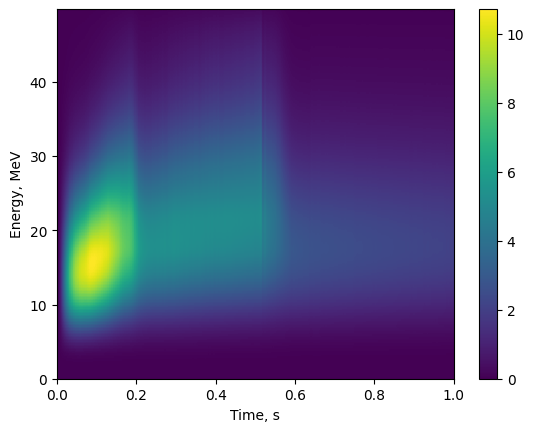

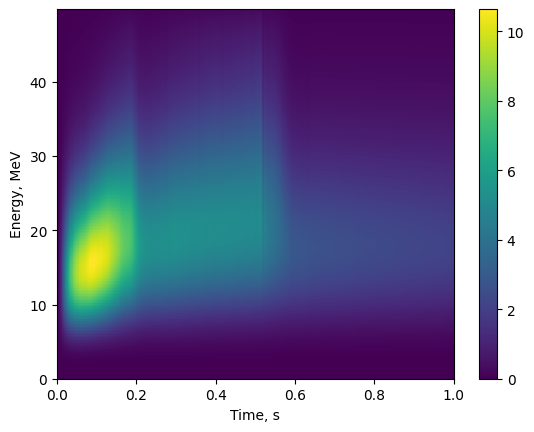

In [6]:
rates = calc_rates()
for rate in rates:
    plot_rate(rate)
    plt.colorbar()
    plt.show()

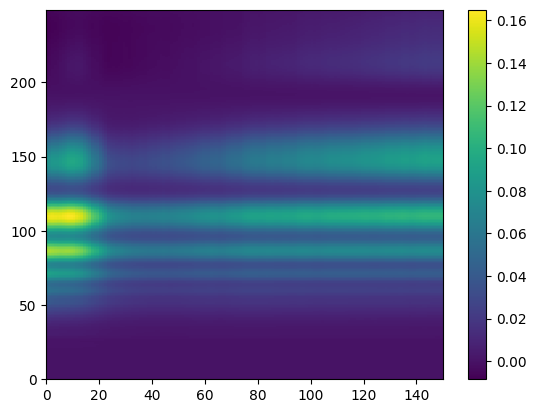

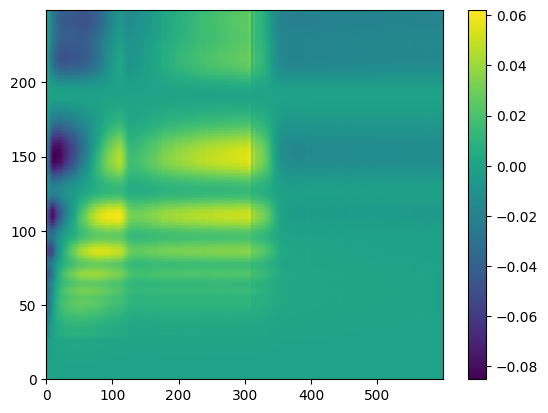

In [8]:
rH1, rH0 = rates[0].array.squeeze(), rates[1].array.squeeze()
ratio = (rH1[100:250]-rH0[100:250])
#print(rH1)
#print(sum(rH1))
plt.pcolormesh(ratio.T)
plt.colorbar()
plt.show()

ratio = (rH1-rH0)/np.sqrt(rH0)
plt.pcolormesh(ratio.T)
plt.colorbar()

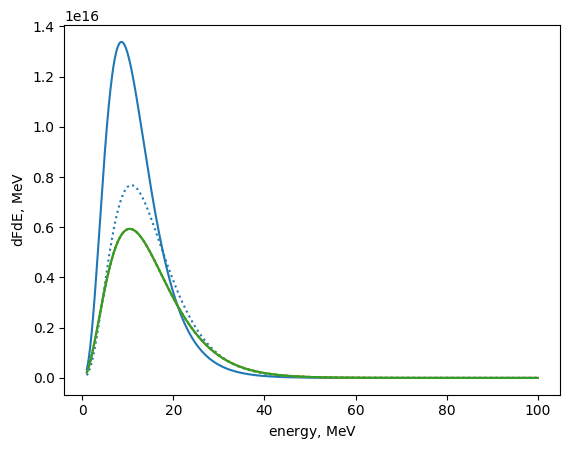



*********************************************************

rho	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Ye	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat

m1	0	dm21^2	7.49e-05	dm32	0.0024381
theta12V	33.68	theta13V	8.56	theta23V	43.3	deltaCP	212

NE	800	Emin	1	Emax	100

output filename stem	:-90,0:7.49e-05,0.0024381,33.68,8.56,43.3,212:800,1,100

Number of domains	13
Domain	1:	0	to	1.2e+06
Domain	2:	1.2e+06	to	2.14e+06
Domain	3:	2.14e+06	to	3.97e+07
Domain	4:	3.97e+07	to	6.67e+07
Domain	5:	6.67e+07	to	2.888e+08
Domain	6:	2.888e+08	to	5.1465e+08
Domain	7:	5.1465e+08	to	7.5895e+08
Domain	8:	7.5895e+08	to	9.848e+08
Domain	9:	9.848e+08	to	1.2069e+09
Domain	10:	1.2069e+09	to	1.2339e+09
Domain	11:	1.2339e+09	to	1.27146e+09
Domain	12:	1.27146e+09	to	1

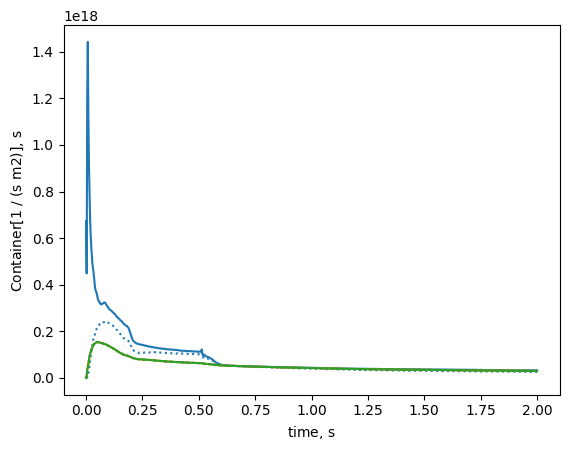

**FlavorMatrix**:<`ThreeFlavor_FlavorBasis`->`ThreeFlavor_FlavorBasis`> shape=(6, 6)

*|$\nu_{e}$|$\nu_{\mu}$|$\nu_{\tau}$|$\overline{\nu}_{e}$|$\overline{\nu}_{\mu}$|$\overline{\nu}_{\tau}$
-:|-:|-:|-:|-:|-:|-:
$\nu_{e}$|0.222|0.26|0.518|0|0|0
$\nu_{\mu}$|0.404|0.367|0.229|0|0|0
$\nu_{\tau}$|0.374|0.373|0.253|0|0|0
$\overline{\nu}_{e}$|0|0|0|0.67|0.308|0.022
$\overline{\nu}_{\mu}$|0|0|0|0.162|0.35|0.487
$\overline{\nu}_{\tau}$|0|0|0|0.168|0.341|0.491
---------

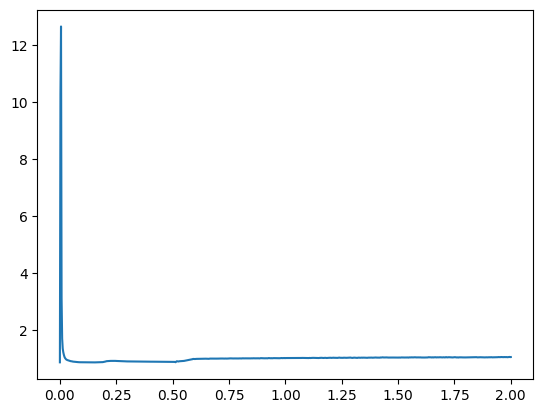

In [12]:
# Пример без осциляций
altaz = AltAz(alt=-90*u.deg, az=0*u.deg)
flavor_transform = EarthMatter(AltAz=altaz, mixing_params=MixingParameters('NORMAL'))
flux0 = model.get_flux(time, energy, distance=1*u.kpc) # поток без осциляций
flux0.plot()
plt.show()
M = flavor_transform.P_ff(t=flux0.time, E=flux0.energy)# вероятность перехода а-б (матрица смещивания[6x6], время, энергия)
print(M)

from snewpy.utils import expand_dimensions_to 
flux1 = flavor_transform.apply_to(flux0)
print(flux0, flux1) # (ароматы 6, время 600, энергия 201)
flux0.plot('time') # временная эволюция всех ароматов без осциляций(изменение потока во времени)
plt.show()
t,r0=flux0['E_BAR'].project_to('time')
t,r1=flux1['E_BAR'].project_to('time')
plt.plot(t, r1.array.squeeze()/r0.array.squeeze())

expand_dimensions_to(M.array,ndim=flux0.array.ndim+1).shape

M[:,:,0,101] # выводит матрицу смешивания

/mnt/d/jinr/SNEWPY/snewpy_venv/lib/python3.10/site-packages/numpy/_core/getlimits.py:551: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)




*********************************************************

rho	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Ye	/mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.rho.dat
Loading a file Thrown in the function Read by the object /mnt/d/jinr/SNEWPY/BEMEWS/src/BEMEWS/data/PREM.Ye.dat

m1	0	dm21^2	7.49e-05	dm32	0.0024381
theta12V	33.68	theta13V	8.56	theta23V	43.3	deltaCP	212

NE	51	Emin	0	Emax	100

output filename stem	:-90,0:7.49e-05,0.0024381,33.68,8.56,43.3,212:51,0,100

Number of domains	13
Domain	1:	0	to	1.2e+06
Domain	2:	1.2e+06	to	2.14e+06
Domain	3:	2.14e+06	to	3.97e+07
Domain	4:	3.97e+07	to	6.67e+07
Domain	5:	6.67e+07	to	2.888e+08
Domain	6:	2.888e+08	to	5.1465e+08
Domain	7:	5.1465e+08	to	7.5895e+08
Domain	8:	7.5895e+08	to	9.848e+08
Domain	9:	9.848e+08	to	1.2069e+09
Domain	10:	1.2069e+09	to	1.2339e+09
Domain	11:	1.2339e+09	to	1.27146e+09
Domain	12:	1.27146e+09	to	1.2

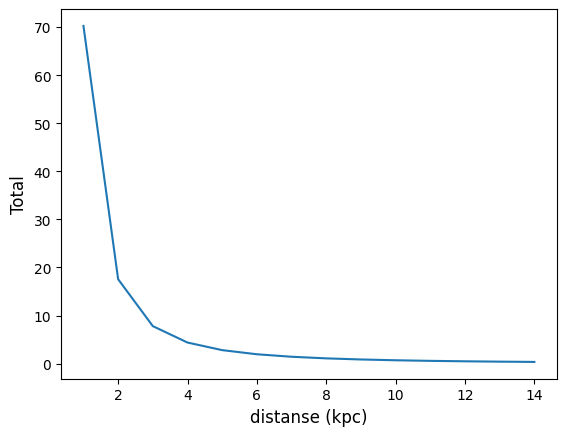

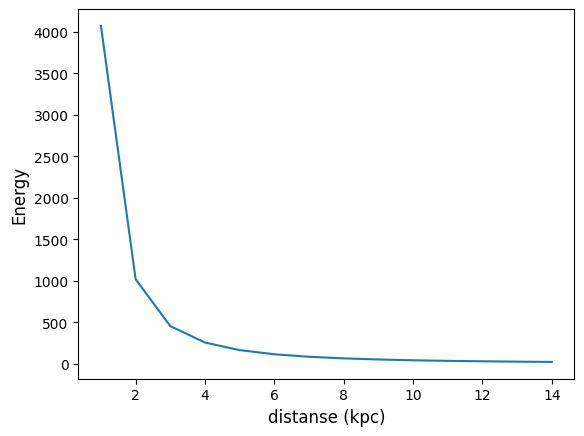

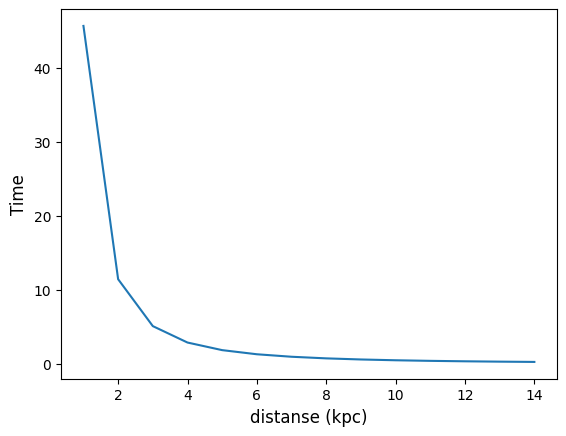

In [1]:
delt_T = []
delt_E = []
delt = []
dist = range(1,15)
for dis in dist:
    #calculate the flux
    flux_earth_earth = model.get_flux(time, energy, distance=dis*u.kpc, flavor_xform=flavor_transform_earth)
    flux_earth_nh = model.get_flux(time, energy, distance=dis*u.kpc, flavor_xform=flavor_transform_nh)
    
    #calculate the event rates using the RateCalculator
    ibd_rate_earth = det.run(flux_earth_earth)['ibd'] 
    ibd_rate = det.run(flux_earth_nh)['ibd']
    
    #get the total values vs. time bin
    N_ibd_T = ibd_rate.integrate_or_sum('time')
    N_ibd_T_earth = ibd_rate_earth.integrate_or_sum('time')
    peak_T, peak_T_earth = max(N_ibd_T.array.squeeze()), max(N_ibd_T_earth.array.squeeze())
    #or total values vs. energy bin
    N_ibd_E = ibd_rate.sum('energy')
    N_ibd_E_earth = ibd_rate_earth.sum('energy')
    peak_E, peak_E_earth = max(N_ibd_E.array.squeeze()), max(N_ibd_E_earth.array.squeeze())
    #or total number of interactions
    N_ibd_tot = ibd_rate.integrate_or_sum('time').sum('energy')
    N_ibd_tot_earth = ibd_rate_earth.integrate_or_sum('time').sum('energy')
    delt.append(N_ibd_tot_earth.array.squeeze()-N_ibd_tot.array.squeeze())
    delt_E.append(peak_E_earth.value-peak_E.value)
    delt_T.append(peak_T_earth.value-peak_T.value)

    print(dis, "килопарсек")
    print(f"{N_ibd_tot.array.squeeze():.2f}", f"{N_ibd_tot_earth.array.squeeze():.2f}", f"{N_ibd_tot_earth.array.squeeze()-N_ibd_tot.array.squeeze():.5f}")
    print(f"{peak_E:.2f}", f"{peak_E_earth:.2f}", f"{peak_E_earth-peak_E:.7f}")
    print(f"{peak_T:.3f}", f"{peak_T_earth:.3f}", f"{peak_T_earth-peak_T:.7f}")
    '''
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # ---- График временного профиля ----
    x_time, dN_time = ibd_rate_earth.project_to('time')
    ax1.plot(x_time.value, dN_time.array.squeeze())
    ax1.set_xlabel(f'time, {x_time.unit._repr_latex_()}')
    ax1.set_ylabel(dN_time.unit._repr_latex_())
    ax1.grid(True, alpha=0.3)
    
    # ---- График энергетического спектра ----
    x_energy, dN_energy = ibd_rate_earth.project_to('energy')
    ax2.stairs(edges=x_energy.value, values=dN_energy.array.squeeze())
    ax2.set_xlabel(f'Energy, {x_energy.unit._repr_latex_()}')
    ax2.set_ylabel(dN_energy.unit._repr_latex_())
    ax2.grid(True, alpha=0.3)
    
    # Автоматическая подгонка отступов
    plt.tight_layout()
    plt.show()
    '''

plt.plot(dist, delt)
plt.xlabel('distanse (kpc)', fontsize=12)
plt.ylabel('Total', fontsize=12)
plt.show()
plt.plot(dist, delt_E)
plt.xlabel('distanse (kpc)', fontsize=12)
plt.ylabel('Energy', fontsize=12)
plt.show()
plt.plot(dist, delt_T)
plt.xlabel('distanse (kpc)', fontsize=12)
plt.ylabel('Time', fontsize=12)
plt.show()
#print("Без Земли", "С Землёй", "Разность")